# 🛡️ Laboratorio: Detección de Botnets IoT (Mirai) en PNETLab con N-BaIoT (`AfterImage`) + IA
**Curso:** Inteligencia Artificial para la Ciberseguridad — **Tecsup**  
**Docente:** Godofredo Diaz

---
### Instrucciones en Google Colab:
1. Sube tus 3 archivos capturados en `SOC-Sniffer`: **`benign.pcap`**, **`mirai_scan.pcap`** y **`mirai_syn.pcap`** al panel izquierdo de archivos de Colab (`/content/`).
2. Ejecuta la **Celda 1** para clonar el repositorio e instalar `tshark`, `scapy` y `Kitsune-py` (`AfterImage`).
3. Ejecuta la **Celda 2** para extraer las **115 características estadísticas incrementales de N-BaIoT** y generar `nbaiot_pnetlab.csv`.
4. Ejecuta la **Celda 3** para entrenar y comparar **Random Forest (Supervisado)** vs. **Isolation Forest (No Supervisado)** y obtener el dictamen de **Cuarentena Suave** para el router MikroTik.

In [1]:
# CELDA 1: Instalar dependencias del sistema, librerías Python y Kitsune-py (AfterImage)
!apt-get -qq update && apt-get -qq install -y tshark
!pip -q install scapy numpy pandas scipy scikit-learn matplotlib seaborn
!rm -rf /content/Kitsune-py && git clone -q https://github.com/ymirsky/Kitsune-py.git /content/Kitsune-py
print('✅ Entorno listo: tshark, scapy y Kitsune-py instalados correctamente.')

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Preconfiguring packages ...
Selecting previously unselected package libpcap0.8t64:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../00-libpcap0.8t64_1.10.4-4.1ubuntu3.1_amd64.deb ...
Unpacking libpcap0.8t64:amd64 (1.10.4-4.1ubuntu3.1) ...
Selecting previously unselected package libbcg729-0:amd64.
Preparing to unpack .../01-libbcg729-0_1.1.1-2build1_amd64.deb ...
Unpacking libbcg729-0:amd64 (1.1.1-2build1) ...
Selecting previously unselected package libcares2:amd64.
Preparing to unpack .../02-libcares2_1.27.0-1.0ubuntu1.1_amd64.deb ...
Unpacking libcares2:amd64 (1.27.0-1.0ubuntu1.1) ...
Selecting previously unselected package liblua5.2-0:amd64.
Preparing to unpack .../03-liblua5.2-0_5.2.4-3build2_amd64.deb ...
Unpacking liblua5.2-0:amd64 (5.2.4-3bu

In [5]:
# CELDA 2: Extraer las 115 características estadísticas de N-BaIoT (AfterImage)
import sys
import types
import warnings
from pathlib import Path

# Solución al error de compatibilidad con NumPy 2.0+ (Kitsune-py utiliza np.Inf obsoleto)
import numpy as np
if not hasattr(np, 'Inf'):
    np.Inf = np.inf

warnings.filterwarnings('ignore', category=SyntaxWarning)
try:
    import pyximport
except ImportError:
    _dummy = types.ModuleType('pyximport')
    _dummy.install = lambda *a, **kw: None
    sys.modules['pyximport'] = _dummy

sys.path.append('/content/Kitsune-py')

import pandas as pd
from FeatureExtractor import FE


def pcap_a_dataframe(ruta_pcap: str, etiqueta: int, escenario: str) -> pd.DataFrame:
    tsv_tmp = Path(f'{ruta_pcap}.tsv')
    if tsv_tmp.exists():
        tsv_tmp.unlink()
    extractor = FE(ruta_pcap, limit=np.inf)
    columnas = extractor.nstat.getNetStatHeaders()
    filas = []

    while True:
        vector = extractor.get_next_vector()
        if len(vector) == 0:
            break
        filas.append(vector)

    df = pd.DataFrame(filas, columns=columnas)
    df['label'] = etiqueta
    df['scenario'] = escenario
    return df


df_0 = pcap_a_dataframe('benign.pcap', etiqueta=0, escenario='benign')
df_1a = pcap_a_dataframe('mirai_scan.pcap', etiqueta=1, escenario='mirai_scan')
df_1b = pcap_a_dataframe('mirai_syn.pcap', etiqueta=1, escenario='mirai_syn')

df_pnetlab = (
    pd.concat([df_0, df_1a, df_1b], ignore_index=True)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

df_pnetlab.to_csv('nbaiot_pnetlab.csv', index=False)
print('Dataset generado con éxito:', df_pnetlab.shape)
print('\nDistribución por clase (0=Benigno, 1=Mirai):')
print(df_pnetlab['label'].value_counts())
print('\nDistribución por escenario:')
print(df_pnetlab['scenario'].value_counts())

Importing Scapy Library
Parsing with tshark...
tshark parsing complete. File saved as: benign.pcap.tsv
counting lines in file...
There are 1208 Packets.
Parsing with tshark...
tshark parsing complete. File saved as: mirai_scan.pcap.tsv
counting lines in file...
There are 1082 Packets.
Parsing with tshark...
tshark parsing complete. File saved as: mirai_syn.pcap.tsv
counting lines in file...
There are 16021 Packets.
Dataset generado con éxito: (18308, 102)

Distribución por clase (0=Benigno, 1=Mirai):
label
1    17101
0     1207
Name: count, dtype: int64

Distribución por escenario:
scenario
mirai_syn     16020
benign         1207
mirai_scan     1081
Name: count, dtype: int64


,Modelo,Exactitud (Accuracy),Precisión,Recall,F1-Score,FPR,TP,TN,FP,FN
0,Random Forest (Supervisado),0.9996,0.9996,1.0,0.9998,0.0055,5131,360,2,0
1,Isolation Forest (No Supervisado),0.9953,0.9950,1.0,0.9975,0.0718,5131,336,26,0



🔥 Top 5 Características N-BaIoT más discriminantes:
HH_0.1_mean_0         0.066627
HH_1_magnitude_0_1    0.066624
MI_dir_5_mean         0.066613
MI_dir_0.01_mean      0.060007
MI_dir_1_mean         0.059989


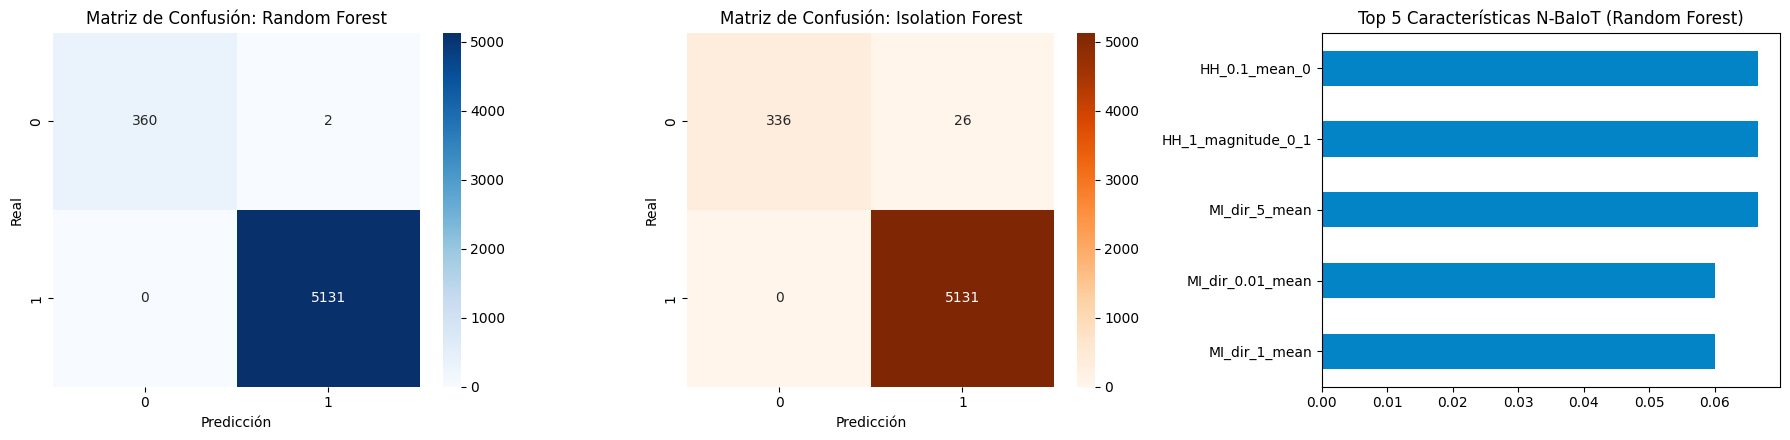

In [6]:
# CELDA 3: Entrenamiento y Comparación (Random Forest vs. Isolation Forest)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('nbaiot_pnetlab.csv')
drop_cols = [c for c in ['label', 'scenario'] if c in df.columns]
X = df.drop(columns=drop_cols).replace([np.inf, -np.inf], np.nan).fillna(0.0)
y = df['label'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 1. Random Forest (Supervisado)
rf = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# 2. Isolation Forest (No Supervisado - entrenado solo con tráfico benigno)
scaler = StandardScaler()
X_train_benign = scaler.fit_transform(X_train[y_train == 0])
X_test_scaled = scaler.transform(X_test)

iso = IsolationForest(n_estimators=150, contamination=0.05, random_state=42)
iso.fit(X_train_benign)
y_pred_iso = np.where(iso.predict(X_test_scaled) == -1, 1, 0)

def evaluar(y_true, y_pred, nombre):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'Modelo': nombre,
        'Exactitud (Accuracy)': round(accuracy_score(y_true, y_pred), 4),
        'Precisión': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1-Score': round(f1_score(y_true, y_pred, zero_division=0), 4),
        'FPR': round(fp / (fp + tn) if (fp + tn) > 0 else 0.0, 4),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
    }

res_df = pd.DataFrame([
    evaluar(y_test, y_pred_rf, 'Random Forest (Supervisado)'),
    evaluar(y_test, y_pred_iso, 'Isolation Forest (No Supervisado)')
])
display(res_df)

# Top 5 Características más importantes
top5 = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(5)
print('\n🔥 Top 5 Características N-BaIoT más discriminantes:')
print(top5.to_string())

# Graficar Matrices de Confusión y Top 5 Features
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión: Random Forest')
axes[0].set_xlabel('Predicción'); axes[0].set_ylabel('Real')

sns.heatmap(confusion_matrix(y_test, y_pred_iso), annot=True, fmt='d', cmap='Oranges', ax=axes[1])
axes[1].set_title('Matriz de Confusión: Isolation Forest')
axes[1].set_xlabel('Predicción'); axes[1].set_ylabel('Real')

top5.sort_values().plot(kind='barh', color='#0284c7', ax=axes[2])
axes[2].set_title('Top 5 Características N-BaIoT (Random Forest)')
plt.tight_layout()
plt.show()